# 05. How reliable are the GP uncertainty estimates?

**Purpose.** A GP gives a 95% prediction interval for every molecule. If the
intervals are honest, about 95% of experimental values should fall inside them.
This notebook counts how often that happens for each property, separately for
training and held-out (test) molecules.

**What this notebook produces**

* `Output_Data/uncertainty/coverage_table.csv`: percent of molecules inside the 95% interval.
* `Output_Data/uncertainty/95_CI_allProps.png` / `.pdf`: the coverage bar chart (600 dpi).
* `Output_Data/uncertainty/results_summary.md`: the results in plain sentences.

**Inputs needed.** The pooled cross-validation predictions from
`04_Final_GCGP_CrossValidation.ipynb`. A copy of the predictions from an
earlier full run (the original Colab notebooks) is kept in
`Input_Data/reference_results/`, for comparison only.

## 1. Environment and setup

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import numpy as np
import pandas as pd

from gcgp.settings import (OUTPUT_DIR, REFERENCE_RESULTS_DIR, checkInputs, describeSetup,
                           outputFolder, setGlobalSeed)
from gcgp.properties import PROPERTY_ORDER
from gcgp.finalConfig import RUN_NAMES
from gcgp.metrics import coverageBySet
from gcgp.plotting import plotCoverageBars

setGlobalSeed()
outputDir = outputFolder("uncertainty")
pd.set_option("display.precision", 2)
print(describeSetup())

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
GP workers    : 1 (set GCGP_N_WORKERS to fit restarts in parallel)
Global seed   : 42


## 2. Load the cross-validation predictions

`predictionSource` picks where the predictions come from:

* `"pipeline"`: the files written by notebook 04 in `Output_Data/final_gcgp_cv/`.
* `"reference"`: the earlier Colab run, in `Input_Data/reference_results/`.

In [2]:
predictionSource = "pipeline"

sourceDirs = {
    "pipeline": lambda run: OUTPUT_DIR / "final_gcgp_cv" / run,
    "reference": lambda run: REFERENCE_RESULTS_DIR,
}

if predictionSource == "reference":
    checkInputs(("reference_results",))

predictionTables = {}
for code in PROPERTY_ORDER:
    runName = RUN_NAMES[code]
    path = sourceDirs[predictionSource](runName) / f"{runName}_all_cv_predictions.csv"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run notebook 04 first, "
                                "or set predictionSource = 'reference'.")
    predictionTables[code] = pd.read_csv(path)

{code: table.shape for code, table in predictionTables.items()}

{'Tb': (8860, 7),
 'Tm': (18390, 7),
 'Pc': (750, 7),
 'Vc': (690, 7),
 'Tc': (700, 7),
 'Hvap': (700, 7),
 'logP': (29780, 7)}

## 3. Coverage of the 95% intervals

A molecule is "inside" when |experimental − predicted| ≤ the 95% half-width.

With only about 70 test molecules for Pc, Vc, Tc and ΔHvap, the observed
coverage is itself uncertain. The last two columns give a 95% Wilson confidence
interval for the test coverage. If this interval does not contain 95%, the
difference from the target is unlikely to be chance.

In [3]:
def wilsonInterval(successes, n, z=1.96):
    """95% Wilson score interval for a proportion, in percent."""
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    halfWidth = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (centre - halfWidth), 100 * (centre + halfWidth)


rows = []
for code, table in predictionTables.items():
    cov = coverageBySet(table)
    low, high = wilsonInterval(round(cov["Test"] / 100 * cov["nTest"]), cov["nTest"])
    rows.append({"Property": code, "Train": cov["Train"], "Test": cov["Test"],
                 "nTestMolecules": cov["nTest"], "Test 95% CI low": low, "Test 95% CI high": high})

coverageDf = pd.DataFrame(rows).set_index("Property")
coverageDf.to_csv(outputDir / "coverage_table.csv")
coverageDf

,Train,Test,nTestMolecules,Test 95% CI low,Test 95% CI high
Property,,,,,
Tb,94.06,93.79,886,92.01,95.20
Tm,94.80,94.67,1839,93.55,95.61
Pc,95.26,89.33,75,80.34,94.50
Vc,95.01,92.75,69,84.13,96.87
Tc,93.17,90.00,70,80.77,95.07
Hvap,99.37,92.86,70,84.34,96.91
logP,98.37,94.19,2978,93.29,94.98


## 4. Coverage figure

Blue bars are training molecules, red bars are held-out test molecules. The
default uses a broken axis. Set `brokenAxis =
False` for a single continuous axis starting at 80% with a line at the 95%
target, which is easier to read.

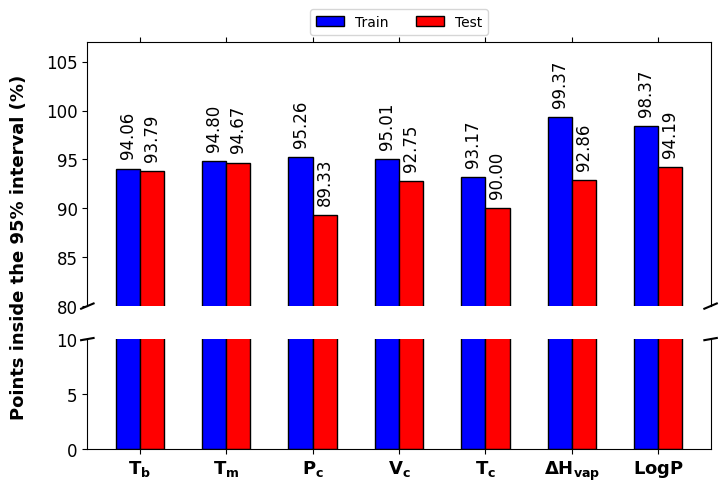

In [4]:
brokenAxis = True

labels = [r"$\mathbf{T_b}$", r"$\mathbf{T_m}$", r"$\mathbf{P_c}$", r"$\mathbf{V_c}$",
          r"$\mathbf{T_c}$", r"$\mathbf{\Delta H_{vap}}$", r"$\mathbf{LogP}$"]
plotCoverageBars(coverageDf.loc[PROPERTY_ORDER], labels,
                 savePath=outputDir / "95_CI_allProps.png", brokenAxis=brokenAxis)

## 5. Summary of the results

Written from the coverage table above. Training coverage above 95% is expected
for a GP, because the model has already seen those molecules. Test coverage is
the number that matters, judged against its Wilson interval.

In [5]:
from gcgp.narrative import describeCoverage, showAndSave

showAndSave(describeCoverage(coverageDf), outputDir / f"results_summary_{predictionSource}.md");

## Coverage of the 95% prediction intervals: results

- **Tb**: 93.8% of 886 test molecules inside the interval (95% CI 92.0–95.2%), consistent with 95%; training coverage 94.1%.
- **Tm**: 94.7% of 1839 test molecules inside the interval (95% CI 93.5–95.6%), consistent with 95%; training coverage 94.8%.
- **Pc**: 89.3% of 75 test molecules inside the interval (95% CI 80.3–94.5%), below 95% (intervals too narrow); training coverage 95.3%.
- **Vc**: 92.8% of 69 test molecules inside the interval (95% CI 84.1–96.9%), consistent with 95%; training coverage 95.0%.
- **Tc**: 90.0% of 70 test molecules inside the interval (95% CI 80.8–95.1%), consistent with 95%; training coverage 93.2%.
- **ΔHvap**: 92.9% of 70 test molecules inside the interval (95% CI 84.3–96.9%), consistent with 95%; training coverage 99.4%.
- **log P**: 94.2% of 2978 test molecules inside the interval (95% CI 93.3–95.0%), below 95% (intervals too narrow); training coverage 98.4%.

Test coverage is significantly below 95% for Pc, log P.
